# 05 — RUL Robustness and Near-Failure Risk (FD002 & FD004)

**Purpose:** Investigate why FD002/FD004 remained difficult in Iteration 2. Test RUL caps **100, 125, 150**, compare temporal-trend versus operating-regime features, repeat **engine-disjoint validation**, and evaluate optimistic errors near failure.

**Evaluation rules:** Hyperparameters, feature selection, and the optional conservative correction are selected **only from training-engine validation**. No test labels are used to choose a model. The 100-cycle horizon is held fixed when comparing different training caps.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

DATASETS = ["FD002", "FD004"]
CAPS = [100, 125, 150]
VARIANTS = ["RF + trends", "RF + regimes"]
SPLIT_SEEDS = [42, 52, 62]  # independent engine-group splits
RANDOM_STATE = 42
ROLLING_WINDOW = 5
N_ESTIMATORS = 80   # raise to 150/300 for a more expensive final run
NEAR_FAILURE = 30
COMMON_HORIZON = 100
# Penalty: overestimations when actual RUL <=30 count twice in the loss.
NEAR_OVER_PENALTY = 2.0
# Conservative offsets are learned ONLY on validation data.
OFFSETS = [0, 3, 5, 8, 10, 15]

HERE = Path.cwd()
PROJECT_ROOT = HERE.parent if (HERE.parent / "data" / "raw").exists() else HERE
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUT = PROJECT_ROOT / "results" / "metrics"
FIG = PROJECT_ROOT / "results" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
setting_cols = [f"setting_{i}" for i in range(1,4)]
sensor_cols = [f"sensor_{i}" for i in range(1,22)]
columns = ["engine_id", "cycle"] + setting_cols + sensor_cols

missing = [str(DATA_DIR / f"{p}_{ds}.txt") for ds in DATASETS
           for p in ("train", "test", "RUL")
           if not (DATA_DIR / f"{p}_{ds}.txt").is_file()]
if missing:
    raise FileNotFoundError("Place NASA C-MAPSS files under data/raw:\n" + "\n".join(missing))
print("Project root:", PROJECT_ROOT)
print("Official test is reserved until model selection is complete.")

Project root: /Users/aisha/mma3001-project
Official test is reserved until model selection is complete.


## 1. Read trajectories and compute uncapped training RUL

Train engines run to failure. For official test engines, ground-truth RUL is given separately, and only the **last visible cycle per engine** is evaluated.

In [2]:
def load_subset(ds):
    train = pd.read_csv(DATA_DIR / f"train_{ds}.txt", sep=r"\s+", header=None, names=columns)
    test = pd.read_csv(DATA_DIR / f"test_{ds}.txt", sep=r"\s+", header=None, names=columns)
    rul = pd.read_csv(DATA_DIR / f"RUL_{ds}.txt", sep=r"\s+", header=None, names=["actual_RUL"])
    train = train.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    test = test.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    train["RUL_raw"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]
    rul["engine_id"] = np.arange(1, len(rul) + 1)
    if len(rul) != test.engine_id.nunique():
        raise ValueError(f"{ds}: RUL labels do not match official test engines")
    return train, test, rul

train_sets = {ds: load_subset(ds)[0] for ds in DATASETS}
for ds, df in train_sets.items():
    print(f"{ds}: {df.engine_id.nunique()} training engines, {len(df):,} cycles")

FD002: 260 training engines, 53,759 cycles
FD004: 249 training engines, 61,249 cycles


## 2. Causal sensor features and operating-condition normalisation

All rolling features look **backwards only**, per engine. Regime fitting uses only the fitting partition (never validation or test). This follows Iteration 2 so results are comparable.

In [3]:
def temporal_features(df, sensors, trends):
    df = df.sort_values(["engine_id", "cycle"]).copy()
    g = df.groupby("engine_id", sort=False)
    extra = {}
    for s in sensors:
        extra[f"{s}_rolling_mean"] = g[s].transform(lambda x: x.rolling(ROLLING_WINDOW, min_periods=1).mean())
        extra[f"{s}_rolling_std"] = g[s].transform(lambda x: x.rolling(ROLLING_WINDOW, min_periods=1).std()).fillna(0)
        extra[f"{s}_delta"] = g[s].diff().fillna(0)
        if trends:
            extra[f"{s}_slope"] = g[s].transform(
                lambda x: (x - x.shift(ROLLING_WINDOW - 1)) /
                np.minimum(np.arange(len(x)), ROLLING_WINDOW - 1).clip(min=1)).fillna(0)
            extra[f"{s}_change_from_start"] = df[s] - g[s].transform("first")
    return pd.concat([df, pd.DataFrame(extra, index=df.index)], axis=1)


def build_features(fit_raw, other_raw, variant):
    sensors = [s for s in sensor_cols if fit_raw[s].std() > 1e-8]
    trends = variant == "RF + trends"
    fit = temporal_features(fit_raw, sensors, trends)
    other = temporal_features(other_raw, sensors, trends)
    suffixes = ["rolling_mean", "rolling_std", "delta"]
    if trends:
        suffixes += ["slope", "change_from_start"]
    features = ["cycle"] + setting_cols + sensors + [f"{s}_{v}" for s in sensors for v in suffixes]
    if variant == "RF + regimes":
        scaler = StandardScaler().fit(fit[setting_cols])
        kmeans = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit(scaler.transform(fit[setting_cols]))
        fit["operating_regime"] = kmeans.predict(scaler.transform(fit[setting_cols]))
        other["operating_regime"] = kmeans.predict(scaler.transform(other[setting_cols]))
        features += ["operating_regime"]
        for s in sensors:
            stats = fit.groupby("operating_regime")[s].agg(["mean", "std"])
            fallback = max(float(fit[s].std()), 1e-8)
            for frame in (fit, other):
                mean = frame["operating_regime"].map(stats["mean"])
                std = frame["operating_regime"].map(stats["std"]).fillna(fallback).clip(lower=1e-8)
                frame[f"{s}_regime_z"] = (frame[s] - mean) / std
            features.append(f"{s}_regime_z")
    return fit, other, features


def new_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestRegressor(n_estimators=N_ESTIMATORS, min_samples_leaf=4,
                                     max_features="sqrt", max_depth=None,
                                     n_jobs=-1, random_state=RANDOM_STATE)),
    ])

## 3. Realistic engine-disjoint validation snapshots

For each validation engine, sample **one observation cutoff** between 40% and 100% of its recorded lifespan. Build features using only observations **up to that cutoff**, just as test engines are only observed to a stopping point. The true remaining life at that point is known in training data. Repeat with three different engine splits. (The snapshot cutoff selection is a validation design choice, not a model input.)

In [4]:
def validation_snapshots(val_raw, seed):
    rng = np.random.default_rng(seed)
    cutoffs = {}
    for engine, group in val_raw.groupby("engine_id"):
        max_cycle = int(group["cycle"].max())
        low = max(1, int(np.ceil(0.40 * max_cycle)))
        cutoffs[engine] = int(rng.integers(low, max_cycle + 1))
    # truncate BEFORE engineering features; avoids ever looking beyond observation
    partial = val_raw.loc[val_raw["cycle"] <= val_raw["engine_id"].map(cutoffs)].copy()
    return partial


def score(y_raw, predictions, cap):
    y_raw = np.asarray(y_raw, dtype=float)
    p = np.asarray(predictions, dtype=float)
    common_y = np.minimum(y_raw, COMMON_HORIZON)
    common_p = np.minimum(p, COMMON_HORIZON)
    err = p - y_raw
    common_err = common_p - common_y
    near = y_raw <= NEAR_FAILURE
    optimistic = near & (err > 0)
    weights = np.where(optimistic, NEAR_OVER_PENALTY, 1.0)
    return {
        "raw_MAE": float(np.mean(np.abs(err))),
        "raw_RMSE": float(np.sqrt(np.mean(err**2))),
        "common100_RMSE": float(np.sqrt(np.mean(common_err**2))),
        "near_MAE": float(np.mean(np.abs(err[near]))) if near.any() else np.nan,
        "near_bias": float(np.mean(err[near])) if near.any() else np.nan,
        "near_over_fraction": float(np.mean(err[near] > 0)) if near.any() else np.nan,
        "risk_score": float(np.sqrt(np.average(common_err**2, weights=weights))),
        "n_near": int(near.sum()),
    }

records = []
oof = []
for ds in DATASETS:
    df = train_sets[ds]
    print(f"\n{ds}")
    for seed in SPLIT_SEEDS:
        split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
        fit_idx, val_idx = next(split.split(df, groups=df.engine_id))
        fit_raw, val_raw = df.iloc[fit_idx].copy(), df.iloc[val_idx].copy()
        assert set(fit_raw.engine_id).isdisjoint(set(val_raw.engine_id))
        val_partial = validation_snapshots(val_raw, seed)
        for variant in VARIANTS:
            fit, val, features = build_features(fit_raw, val_partial, variant)
            last = val.groupby("engine_id", as_index=False).tail(1).sort_values("engine_id")
            for cap in CAPS:
                model = new_model().fit(fit[features], fit["RUL_raw"].clip(upper=cap))
                pred = np.clip(model.predict(last[features]), 0, cap)
                scores = score(last.RUL_raw, pred, cap)
                records.append({"dataset": ds, "seed": seed, "variant": variant, "cap": cap,
                                "n_engines": len(last), **scores})
                oof.append(pd.DataFrame({"dataset": ds, "seed": seed, "variant": variant,
                                         "cap": cap, "engine_id": last.engine_id.to_numpy(),
                                         "actual_RUL": last.RUL_raw.to_numpy(), "predicted_RUL": pred}))
        print("  completed seed", seed)

validation = pd.DataFrame(records)
validation.to_csv(OUT / "iteration5_validation_by_split.csv", index=False)
validation_predictions = pd.concat(oof, ignore_index=True)
validation_predictions.to_csv(OUT / "iteration5_validation_predictions.csv", index=False)
display(validation.round(2))


FD002
  completed seed 42
  completed seed 52
  completed seed 62

FD004
  completed seed 42
  completed seed 52
  completed seed 62


,dataset,seed,variant,cap,n_engines,raw_MAE,raw_RMSE,common100_RMSE,near_MAE,near_bias,near_over_fraction,risk_score,n_near
0,FD002,42,RF + trends,100,52,15.35,19.26,15.40,16.14,16.14,1.00,16.26,17
1,FD002,42,RF + trends,125,52,18.14,21.84,17.91,17.01,17.01,1.00,18.16,17
2,FD002,42,RF + trends,150,52,19.75,23.79,18.85,17.47,17.47,1.00,19.11,17
3,FD002,42,RF + regimes,100,52,15.96,20.56,16.64,15.62,15.62,1.00,17.13,17
4,FD002,42,RF + regimes,125,52,17.82,22.10,18.56,16.26,16.26,1.00,18.83,17
5,FD002,42,RF + regimes,150,52,19.98,24.88,19.19,16.87,16.87,1.00,19.44,17
6,FD002,52,RF + trends,100,52,17.72,21.92,16.77,9.73,9.73,1.00,15.99,11
7,FD002,52,RF + trends,125,52,17.71,23.01,19.59,11.56,11.56,1.00,18.85,11
8,FD002,52,RF + trends,150,52,18.93,23.75,19.37,12.05,12.05,1.00,18.66,11
9,FD002,52,RF + regimes,100,52,17.54,22.49,17.55,7.43,7.43,1.00,16.46,11


## 4. Model selection: comparable horizon + risk

Select a feature variant and cap for **each dataset** using validation only. The default decision rule minimises a **common 100-cycle weighted RMSE** that counts optimistic near-failure errors twice. Since all configurations use the *same* 100-cycle scoring horizon, caps can be compared fairly. Raw-RUL RMSE is reported but is not the primary selection target.

Overlapping engines across different validation splits mean the split averages are **not independent confidence intervals**.

In [5]:
summary = (validation.groupby(["dataset", "variant", "cap"], as_index=False)
           .agg(risk_score=("risk_score", "mean"),
                risk_sd=("risk_score", "std"),
                common100_RMSE=("common100_RMSE", "mean"),
                raw_RMSE=("raw_RMSE", "mean"),
                near_MAE=("near_MAE", "mean"),
                near_bias=("near_bias", "mean")))
summary = summary.sort_values(["dataset", "risk_score", "common100_RMSE"]).reset_index(drop=True)
choices = summary.groupby("dataset", as_index=False).first()
summary.to_csv(OUT / "iteration5_validation_summary.csv", index=False)
choices.to_csv(OUT / "iteration5_model_choices.csv", index=False)
display(summary.round(2))
print("SELECTED CONFIGURATIONS (validation only):")
display(choices[["dataset", "variant", "cap", "risk_score", "common100_RMSE", "near_bias"]].round(2))

,dataset,variant,cap,risk_score,risk_sd,common100_RMSE,raw_RMSE,near_MAE,near_bias
0,FD002,RF + trends,100,17.17,1.81,17.15,22.22,13.73,13.73
1,FD002,RF + regimes,100,17.70,1.61,17.92,22.81,12.30,12.30
2,FD002,RF + regimes,125,19.29,1.81,19.90,24.05,12.37,12.37
3,FD002,RF + trends,125,19.57,1.87,19.78,23.70,14.67,14.67
4,FD002,RF + regimes,150,19.79,1.55,20.35,25.96,13.02,13.02
5,FD002,RF + trends,150,19.90,1.78,20.27,25.06,14.72,14.72
6,FD004,RF + trends,100,16.64,1.11,16.75,36.15,10.84,10.19
7,FD004,RF + regimes,100,16.65,0.90,16.87,36.08,9.19,8.49
8,FD004,RF + regimes,125,17.64,0.60,17.97,32.83,9.41,8.68
9,FD004,RF + trends,125,18.07,1.77,18.33,32.70,11.66,11.06


SELECTED CONFIGURATIONS (validation only):


,dataset,variant,cap,risk_score,common100_RMSE,near_bias
0,FD002,RF + trends,100,17.17,17.15,13.73
1,FD004,RF + trends,100,16.64,16.75,10.19


## 5. Optional conservative adjustment (selected on validation only)

Try small **downward offsets** to reduce overestimation. Choose the offset with the best common-horizon risk score on held-out validation predictions, **not** on official test predictions. An offset can reduce optimism but may increase underestimation and overall RMSE. There is no guarantee of real-world safety.

In [6]:
offset_results = []
selected_offsets = {}
for ds in DATASETS:
    chosen = choices.loc[choices.dataset == ds].iloc[0]
    mask = ((validation_predictions.dataset == ds) &
            (validation_predictions.variant == chosen.variant) &
            (validation_predictions.cap == chosen.cap))
    selected_val = validation_predictions.loc[mask]
    for offset in OFFSETS:
        adjusted = np.clip(selected_val.predicted_RUL.to_numpy() - offset, 0, chosen.cap)
        s = score(selected_val.actual_RUL.to_numpy(), adjusted, chosen.cap)
        offset_results.append({"dataset": ds, "offset": offset, **s})
    options = [r for r in offset_results if r["dataset"] == ds]
    selected_offsets[ds] = min(options, key=lambda r: r["risk_score"])["offset"]
offset_comparison = pd.DataFrame(offset_results)
offset_comparison.to_csv(OUT / "iteration5_offset_validation.csv", index=False)
print("Offsets selected from validation:", selected_offsets)
display(offset_comparison.round(2))

Offsets selected from validation: {'FD002': 5, 'FD004': 5}


,dataset,offset,raw_MAE,raw_RMSE,common100_RMSE,near_MAE,near_bias,near_over_fraction,risk_score,n_near
0,FD002,0,17.61,22.37,17.23,14.16,14.16,1.00,17.22,41
1,FD002,3,16.82,22.19,16.37,11.21,11.16,0.98,16.10,41
2,FD002,5,16.45,22.30,16.09,9.37,9.16,0.90,15.73,41
3,FD002,8,16.30,22.79,16.13,7.78,6.17,0.68,15.80,41
4,FD002,10,16.45,23.32,16.45,7.13,4.30,0.59,16.08,41
5,FD002,15,17.77,25.28,18.19,7.03,-0.22,0.32,17.89,41
6,FD004,0,23.88,36.17,16.75,11.56,11.00,0.86,16.71,37
7,FD004,3,23.70,36.94,16.44,9.65,8.00,0.73,16.30,37
8,FD004,5,23.85,37.58,16.53,8.84,6.00,0.68,16.26,37
9,FD004,8,24.50,38.71,17.11,8.35,3.04,0.54,16.75,37


## 6. ONE official test evaluation

At this point configuration and conservative offset are frozen. Refit using the full training dataset. Report raw-RUL metrics, **common 100-cycle** metrics, and near-failure optimism. Evaluate **both unadjusted and adjusted** predictions for transparency.

In [7]:
test_metrics = []
test_predictions = []
for ds in DATASETS:
    selected = choices.loc[choices.dataset == ds].iloc[0]
    train, test, rul = load_subset(ds)
    fit, test_fe, features = build_features(train, test, selected.variant)
    final_rows = test_fe.groupby("engine_id", as_index=False).tail(1).sort_values("engine_id")
    final_rows = final_rows.merge(rul, on="engine_id", how="left", validate="one_to_one")
    assert final_rows.actual_RUL.notna().all()
    model = new_model().fit(fit[features], fit.RUL_raw.clip(upper=int(selected.cap)))
    pred = np.clip(model.predict(final_rows[features]), 0, int(selected.cap))
    offset = selected_offsets[ds]
    adjusted = np.clip(pred - offset, 0, int(selected.cap))
    for label, pp in [("unadjusted", pred), ("conservative_offset", adjusted)]:
        s = score(final_rows.actual_RUL.to_numpy(), pp, selected.cap)
        test_metrics.append({"dataset": ds, "method": label, "variant": selected.variant,
                             "cap": int(selected.cap), "offset": offset if label != "unadjusted" else 0,
                             **s})
    test_predictions.append(pd.DataFrame({"dataset": ds, "engine_id": final_rows.engine_id,
                                          "actual_RUL": final_rows.actual_RUL,
                                          "predicted_unadjusted": pred,
                                          "predicted_adjusted": adjusted,
                                          "final_cycle": final_rows.cycle}))

final_metrics = pd.DataFrame(test_metrics)
final_predictions = pd.concat(test_predictions, ignore_index=True)
final_metrics.to_csv(OUT / "iteration5_official_test_metrics.csv", index=False)
final_predictions.to_csv(OUT / "iteration5_official_test_predictions.csv", index=False)
display(final_metrics.round(2))

,dataset,method,variant,cap,offset,raw_MAE,raw_RMSE,common100_RMSE,near_MAE,near_bias,near_over_fraction,risk_score,n_near
0,FD002,unadjusted,RF + trends,100,0,24.09,34.45,12.47,8.43,7.76,0.82,12.34,61
1,FD002,conservative_offset,RF + trends,100,5,25.48,36.88,13.51,5.79,2.76,0.69,12.92,61
2,FD004,unadjusted,RF + trends,100,0,27.09,37.41,14.01,12.08,11.77,0.92,14.27,53
3,FD004,conservative_offset,RF + trends,100,5,28.36,39.87,14.68,8.30,6.77,0.75,14.45,53


## 7. Visualise performance and near-failure errors

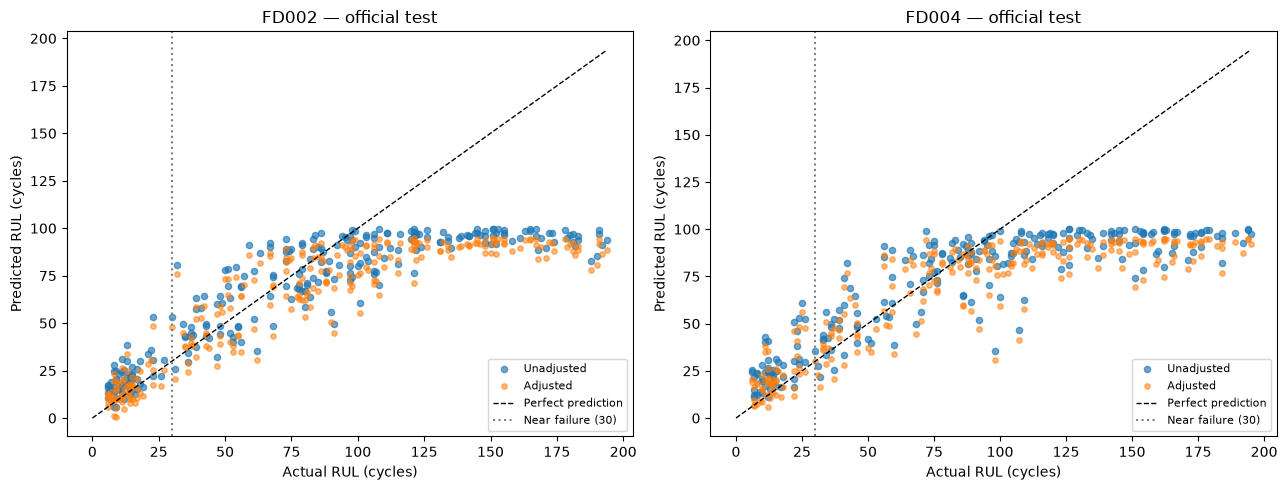

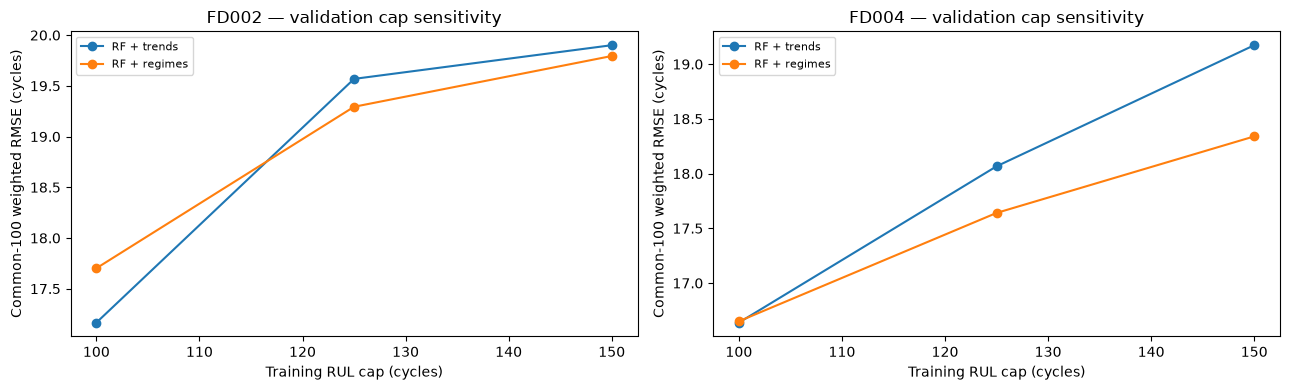

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ds in zip(axes, DATASETS):
    p = final_predictions.loc[final_predictions.dataset == ds]
    ax.scatter(p.actual_RUL, p.predicted_unadjusted, s=20, alpha=.65, label="Unadjusted")
    ax.scatter(p.actual_RUL, p.predicted_adjusted, s=15, alpha=.55, label="Adjusted")
    limit = max(p.actual_RUL.max(), p.predicted_unadjusted.max())
    ax.plot([0, limit], [0, limit], "k--", linewidth=1, label="Perfect prediction")
    ax.axvline(NEAR_FAILURE, color="grey", linestyle=":", label="Near failure (30)")
    ax.set(title=f"{ds} — official test", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "iteration5_predictions.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ds in zip(axes, DATASETS):
    sub = summary.loc[summary.dataset == ds]
    for variant in VARIANTS:
        s = sub.loc[sub.variant == variant].sort_values("cap")
        ax.plot(s.cap, s.risk_score, marker="o", label=variant)
    ax.set(title=f"{ds} — validation cap sensitivity", xlabel="Training RUL cap (cycles)",
           ylabel="Common-100 weighted RMSE (cycles)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "iteration5_cap_sensitivity.png", dpi=160)
plt.show()

## 8. Compare with Iteration 2 without changing the test-derived choice

These previous predictions are **descriptive comparisons only**. Do not use them to retune choices made above, because that would leak official test results into development.

In [9]:
previous = OUT / "multi_dataset_improved_test_metrics.csv"
if not previous.exists():
    previous = PROJECT_ROOT / "multi_dataset_improved_test_metrics.csv"
if previous.exists():
    old = pd.read_csv(previous)
    print("Previous iteration test metrics:")
    display(old[old.dataset.isin(DATASETS)].round(2))
else:
    print("Previous metrics file not found; skip comparison.")
print("\nIteration 5 official test metrics:")
display(final_metrics[["dataset", "method", "raw_RMSE", "common100_RMSE", "near_MAE", "near_bias", "near_over_fraction"]].round(2))

Previous iteration test metrics:


,dataset,model,target,MAE,RMSE,R2,bias
2,FD002,RF + regimes,official raw RUL,23.60,34.24,0.59,-14.85
3,FD002,RF + regimes,RUL capped at 100,8.96,12.40,0.88,-0.22
6,FD004,RF + trends,official raw RUL,27.09,37.37,0.53,-16.58
7,FD004,RF + trends,RUL capped at 100,9.96,14.01,0.84,0.54



Iteration 5 official test metrics:


,dataset,method,raw_RMSE,common100_RMSE,near_MAE,near_bias,near_over_fraction
0,FD002,unadjusted,34.45,12.47,8.43,7.76,0.82
1,FD002,conservative_offset,36.88,13.51,5.79,2.76,0.69
2,FD004,unadjusted,37.41,14.01,12.08,11.77,0.92
3,FD004,conservative_offset,39.87,14.68,8.30,6.77,0.75


## 9. Report notes and limitations

- **Model validation:** split by engine, never by rows; sensor features use only observed history. Training cap and model choice were selected using repeated validation snapshots.
- **Fair comparisons:** compare 100/125/150 training caps using **the same 100-cycle evaluation target** and report uncapped RMSE separately. Capped and uncapped RMSE answer different questions.
- **Safety-relevant diagnostic:** near-failure *signed bias*, MAE, and percentage of overestimates (actual RUL ≤30). Reducing positive bias is not proof of safe maintenance decisions.
- **Evaluation limitation:** the official test set is an independent final check, not a tuning set; snapshot cutoffs (40–100% of a life) are a simplification and may differ from official test stopping times.
- **Reproducibility:** save exported metrics and figures, record split seeds and `N_ESTIMATORS`, and compare against Notebook 04's metrics.

**Suggested next step:** If FD002/FD004 remain weak, discuss why operating changes and multiple fault modes make medium/long-range RUL estimation difficult. You do not need unlimited iterations for a sound engineering report.